# 01 · EDA, species inclusion, folds

Runs locally or on Kaggle.
- Local: competition data unzipped to `data/birdclef-2025/`; `data/animalspeak_*` from `src/exposure.py`. Outputs go to `outputs/eda/`.
- Kaggle: attach `birdclef-2025` and a private dataset with the three `animalspeak_*` files. Outputs go to `/kaggle/working`.

Outputs: `eda_species_all.csv`, `durations.csv`, `species.csv`, `folds.csv`, `match.csv`, `eda_summary.json`.

**Rule:** decide the inclusion thresholds in section 6 from the distributions only — before any model is trained — and copy them into `PREREGISTRATION.md`.

In [20]:
import ast, json, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold

ON_KAGGLE = Path('/kaggle/input').exists()
REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
INPUT = Path('/kaggle/input') if ON_KAGGLE else REPO / 'data'

def find_dir(marker):
    hits = sorted(INPUT.rglob(marker))
    assert hits, f'{marker} not found under {INPUT}'
    return hits[0].parent

COMP = find_dir('taxonomy.csv')            # local: data/birdclef-2025/
AUX = find_dir('animalspeak_species.csv')  # local: data/
OUT = Path('/kaggle/working') if ON_KAGGLE else REPO / 'outputs' / 'eda'
OUT.mkdir(parents=True, exist_ok=True)
SEED = 0
print(COMP, AUX)

/kaggle/input/competitions/birdclef-2025 /kaggle/input/datasets/jeynkim/who-gets-heard-data


## 1. Load and check the schema

In [21]:
train = pd.read_csv(COMP / 'train.csv')
tax = pd.read_csv(COMP / 'taxonomy.csv')
print(train.shape, tax.shape)
print('train.csv:', list(train.columns))
print('taxonomy.csv:', list(tax.columns))
train.head(3)

(28564, 13) (206, 5)
train.csv: ['primary_label', 'secondary_labels', 'type', 'filename', 'collection', 'rating', 'url', 'latitude', 'longitude', 'scientific_name', 'common_name', 'author', 'license']
taxonomy.csv: ['primary_label', 'inat_taxon_id', 'scientific_name', 'common_name', 'class_name']


,primary_label,secondary_labels,type,filename,collection,rating,url,latitude,longitude,scientific_name,common_name,author,license
0,1139490,[''],[''],1139490/CSA36385.ogg,CSA,0.0,http://colecciones.humboldt.org.co/rec/sonidos...,7.3206,-73.7128,Ragoniella pulchella,Ragoniella pulchella,Fabio A. Sarria-S,cc-by-nc-sa 4.0
1,1139490,[''],[''],1139490/CSA36389.ogg,CSA,0.0,http://colecciones.humboldt.org.co/rec/sonidos...,7.3206,-73.7128,Ragoniella pulchella,Ragoniella pulchella,Fabio A. Sarria-S,cc-by-nc-sa 4.0
2,1192948,[''],[''],1192948/CSA36358.ogg,CSA,0.0,http://colecciones.humboldt.org.co/rec/sonidos...,7.3791,-73.7313,Oxyprora surinamensis,Oxyprora surinamensis,Fabio A. Sarria-S,cc-by-nc-sa 4.0


## 2. Taxonomic composition

In [22]:
train = train.merge(tax[['primary_label', 'class_name']], on='primary_label', how='left')
assert train['class_name'].notna().all()
comp = train.groupby('class_name').agg(species=('primary_label', 'nunique'), recordings=('filename', 'size'))
comp

,species,recordings
class_name,,
Amphibia,34,583
Aves,146,27648
Insecta,17,155
Mammalia,9,178


## 3. Birds: recordings, recordists, sources

`author` may be missing; missing authors get a unique group per recording so they don't collapse into one giant group.

In [23]:
birds = train[train['class_name'] == 'Aves'].copy()
missing_author = birds['author'].isna().sum()
birds['group'] = birds['author'].fillna('__na__' + birds['filename'])
print('bird recordings:', len(birds), '| species:', birds['primary_label'].nunique(),
      '| missing author:', missing_author)

sp = birds.groupby('primary_label').agg(
    n_rec=('filename', 'size'),
    n_author=('group', 'nunique'),
    n_unrated=('rating', lambda r: int((r == 0).sum())),
).join(birds.pivot_table(index='primary_label', columns='collection', values='filename',
                         aggfunc='size', fill_value=0).add_prefix('n_'))
sp = sp.join(birds[birds['rating'] > 0].groupby('primary_label')['rating'].mean().rename('mean_rating'))
sp = sp.join(tax.set_index('primary_label')[['scientific_name', 'common_name']])
sp.sort_values('n_rec').describe()

bird recordings: 27648 | species: 146 | missing author: 0


,n_rec,n_author,n_unrated,n_XC,n_iNat,mean_rating
count,146.000000,146.000000,146.000000,146.000000,146.000000,146.000000
mean,189.369863,81.486301,49.287671,144.109589,45.260274,3.966592
std,177.147981,69.553178,77.550425,115.083845,76.540281,0.279216
min,6.000000,3.000000,0.000000,6.000000,0.000000,2.718750
25%,69.250000,36.000000,8.000000,61.250000,5.000000,3.830674
50%,129.500000,55.500000,19.000000,111.000000,15.000000,4.028950
75%,256.500000,106.000000,49.500000,201.250000,41.750000,4.143977
max,990.000000,370.000000,491.000000,500.000000,491.000000,4.509804


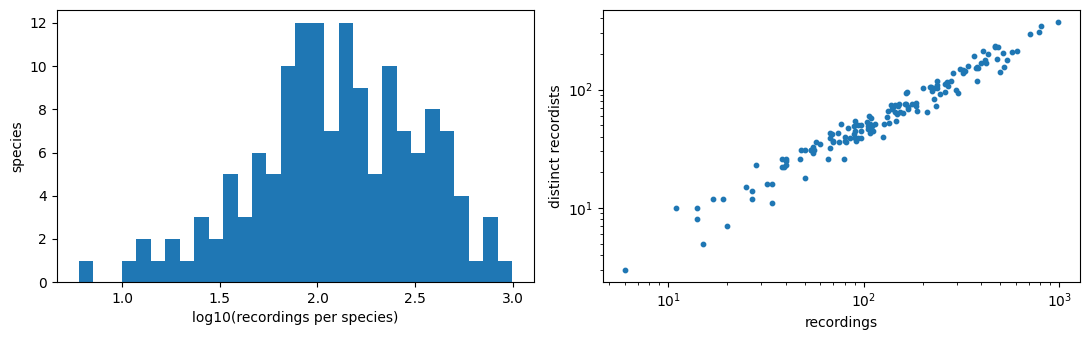

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(np.log10(sp['n_rec']), bins=30)
ax[0].set_xlabel('log10(recordings per species)'); ax[0].set_ylabel('species')
ax[1].scatter(sp['n_rec'], sp['n_author'], s=10)
ax[1].set_xscale('log'); ax[1].set_yscale('log')
ax[1].set_xlabel('recordings'); ax[1].set_ylabel('distinct recordists')
plt.tight_layout(); plt.show()

## 4. Data quality checks

### 4a. `rating` by source
Rating 0 means unrated. If all iNaturalist recordings are 0, a rating filter would delete that whole source, so rating is used only as a covariate: `mean_rating` = mean over rated (> 0) recordings.

In [25]:
print(pd.crosstab(birds['collection'], birds['rating']))
print('species whose XC count hits the 500 cap:', int((sp['n_XC'] >= 500).sum()))

rating       0.0  0.5  1.0  1.5  2.0  2.5   3.0  3.5   4.0   4.5   5.0
collection                                                            
XC           588   26  224   70  741  360  2838  894  7510  1257  6532
iNat        6608    0    0    0    0    0     0    0     0     0     0
species whose XC count hits the 500 cap: 1


### 4b. Secondary labels

In [26]:
def parse_list(s):
    try:
        v = ast.literal_eval(s) if isinstance(s, str) else []
    except (ValueError, SyntaxError):
        return []
    return [x for x in v if str(x).strip()]  # "['']" means no secondary label

birds['n_secondary'] = birds['secondary_labels'].map(parse_list).map(len)
print('share with >=1 secondary label:', round((birds['n_secondary'] > 0).mean(), 3))
birds.groupby('collection')['n_secondary'].apply(lambda s: (s > 0).mean())

share with >=1 secondary label: 0.096


collection
XC      0.125903
iNat    0.000000
Name: n_secondary, dtype: float64

### 4c. Durations
Reads only the file header, so it's fast. Cached to `durations.csv`.

In [27]:
import soundfile as sf
from concurrent.futures import ThreadPoolExecutor

def duration(fn):
    try:
        return sf.info(str(COMP / 'train_audio' / fn)).duration
    except Exception:
        return np.nan

dur_path = OUT / 'durations.csv'
if dur_path.exists():
    dur = pd.read_csv(dur_path)
else:
    with ThreadPoolExecutor(16) as ex:
        secs = list(ex.map(duration, birds['filename']))
    dur = pd.DataFrame({'filename': birds['filename'], 'duration': secs})
    dur.to_csv(dur_path, index=False)

birds = birds.merge(dur, on='filename', how='left')
print('unreadable:', birds['duration'].isna().sum())
print(birds['duration'].describe(percentiles=[.1, .5, .9, .99]))
print('5 s chunks if uncapped:', int(np.ceil(birds['duration'] / 5).sum()))
print('5 s chunks with cap 5   :', int(np.minimum(np.ceil(birds['duration'] / 5), 5).sum()))
sp = sp.join(birds.groupby('primary_label')['duration'].mean().rename('mean_duration'))

unreadable: 0
count    27648.000000
mean        35.028030
std         49.887340
min          0.548000
10%          5.590219
50%         21.013703
90%         74.848650
99%        227.877779
max       1774.392000
Name: duration, dtype: float64
5 s chunks if uncapped: 207537
5 s chunks with cap 5   : 106120


## 5. Match against AnimalSpeak (BioLingual training data)

### 5a. Species-level pretraining frequency

In [28]:
asp = pd.read_csv(AUX / 'animalspeak_species.csv')
meta = json.loads((AUX / 'animalspeak_meta.json').read_text())
norm = lambda s: s.astype(str).str.strip().str.lower().str.replace(r'\s+', ' ', regex=True)

sp['sci'] = norm(sp['scientific_name'])
sp = sp.join(asp.set_index('sci')[['n_total', 'n_xc', 'n_inat']].add_prefix('as_'), on='sci')
unmatched = sp[sp['as_n_total'].isna()]
print(f'species matched in AnimalSpeak: {sp["as_n_total"].notna().sum()} / {len(sp)}')
unmatched[['scientific_name', 'common_name', 'n_rec']]

species matched in AnimalSpeak: 146 / 146


,scientific_name,common_name,n_rec
primary_label,,,


Unmatched names are usually taxonomic renames. Look each one up (e.g. on Avibase / eBird) and add it to `SYNONYMS` as `BirdCLEF name → AnimalSpeak name`; species still unmatched get frequency 0 only if you are sure it is absent, otherwise exclude them from experiment E and report them.

In [29]:
SYNONYMS = {
    # 'birdclef scientific name': 'animalspeak scientific name',
}
if SYNONYMS:
    fix = sp['sci'].map({k.lower(): v.lower() for k, v in SYNONYMS.items()})
    sp.loc[fix.notna(), 'sci'] = fix.dropna()
    sp = sp.drop(columns=['as_n_total', 'as_n_xc', 'as_n_inat'])
    sp = sp.join(asp.set_index('sci')[['n_total', 'n_xc', 'n_inat']].add_prefix('as_'), on='sci')
    print('matched after synonyms:', sp['as_n_total'].notna().sum())

### 5b. Recording-level leakage: seen / unseen / unknown
- **seen**: ID present in AnimalSpeak
- **unseen**: ID greater than the largest ID of that source in AnimalSpeak (Xeno-canto or iNaturalist sound ID; uploaded after the data was collected)
- **unknown**: everything else (some AnimalSpeak XC URLs have no ID, and the public file may be a subset)

First check what BirdCLEF URLs look like:

In [30]:
for c, g in birds.groupby('collection'):
    print(c, g['url'].dropna().head(3).tolist())

XC ['https://xeno-canto.org/113758', 'https://xeno-canto.org/119209', 'https://xeno-canto.org/120034']
iNat ['https://static.inaturalist.org/sounds/1232413.mp3', 'https://static.inaturalist.org/sounds/397661.mp3', 'https://static.inaturalist.org/sounds/472606.m4a']


In [31]:
# Adjust these patterns to the URL formats printed above.
XC_PAT = r'xeno-canto\.org/(\d+)'
INAT_PAT = r'inaturalist\.org/(?:sounds|observations)/(\d+)'

birds['xc_id'] = birds['url'].str.extract(XC_PAT)[0].astype('Int64')
birds['inat_id'] = birds['url'].str.extract(INAT_PAT)[0].astype('Int64')
print(birds.groupby('collection')[['xc_id', 'inat_id']].apply(lambda g: g.notna().mean()))

ids = pd.read_csv(AUX / 'animalspeak_ids.csv')
xc_seen = set(ids.loc[ids['source'] == 'xc', 'id'])
inat_seen = set(ids.loc[ids['source'] == 'inat', 'id'])

def status(r):
    if pd.notna(r['xc_id']):
        if r['xc_id'] in xc_seen: return 'seen'
        if r['xc_id'] > meta['xc_id_max']: return 'unseen'
    if pd.notna(r['inat_id']):
        if r['inat_id'] in inat_seen: return 'seen'
        if r['inat_id'] > meta['inat_id_max']: return 'unseen'
    return 'unknown'

birds['leak'] = birds.apply(status, axis=1)
print(pd.crosstab(birds['collection'], birds['leak'], margins=True))

per_sp = pd.crosstab(birds['primary_label'], birds['leak'])
sp = sp.join(per_sp.add_prefix('leak_'))
print('unseen recordings per species:')
print(sp['leak_unseen'].describe(percentiles=[.1, .25, .5]))
print('species with >= 5 unseen recordings:', int((sp['leak_unseen'] >= 5).sum()))

            xc_id  inat_id
collection                
XC            1.0      0.0
iNat          0.0      1.0
leak         seen  unknown  unseen    All
collection                               
XC          14106     4328    2606  21040
iNat         2362     1484    2762   6608
All         16468     5812    5368  27648
unseen recordings per species:
count    146.000000
mean      36.767123
std       45.603999
min        0.000000
10%        3.000000
25%        9.000000
50%       19.000000
max      279.000000
Name: leak_unseen, dtype: float64
species with >= 5 unseen recordings: 128


BirdCLEF iNat URLs are `static.inaturalist.org/sounds/{id}` — the same sound IDs as AnimalSpeak, so they are matchable.

### 5c. Are training count and pretraining count separable?

Spearman(log n_rec, log AnimalSpeak count) = 0.97 (p = 1e-94)


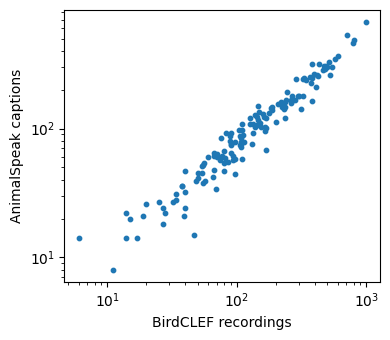

In [32]:
from scipy.stats import spearmanr
r, p = spearmanr(np.log(sp['n_rec']), np.log(sp['as_n_total']), nan_policy='omit')
print(f'Spearman(log n_rec, log AnimalSpeak count) = {r:.2f} (p = {p:.1g})')
plt.figure(figsize=(4, 3.5)); plt.scatter(sp['n_rec'], sp['as_n_total'], s=10)
plt.xscale('log'); plt.yscale('log'); plt.xlabel('BirdCLEF recordings'); plt.ylabel('AnimalSpeak captions')
plt.tight_layout(); plt.show()

## 6. Inclusion thresholds

Look at the grid, then set `MIN_REC` and `MIN_AUTHOR` **once**. Write the reason down in `PREREGISTRATION.md`.

In [33]:
grid = []
for mr in [5, 8, 10, 15, 20]:
    for ma in [2, 3, 4, 5]:
        ok = sp[(sp['n_rec'] >= mr) & (sp['n_author'] >= ma)]
        grid.append(dict(min_rec=mr, min_author=ma, species=len(ok), recordings=int(ok['n_rec'].sum()),
                         min_n_rec=int(ok['n_rec'].min()) if len(ok) else 0))
pd.DataFrame(grid).pivot(index='min_rec', columns='min_author', values='species')

min_author,2,3,4,5
min_rec,,,,
5,146,146,145,145
8,145,145,145,145
10,145,145,145,145
15,142,142,142,142
20,139,139,139,139


In [34]:
MIN_REC, MIN_AUTHOR = 8, 3   # <- decide from the grid above

sp['eligible'] = (sp['n_rec'] >= MIN_REC) & (sp['n_author'] >= MIN_AUTHOR)
inc = sp[sp['eligible']].copy()
exc = sp[~sp['eligible']]
print(f'included: {len(inc)} species, {int(inc.n_rec.sum())} recordings')
print(f'excluded: {len(exc)} species, {int(exc.n_rec.sum())} recordings; '
      f'n_rec range {exc.n_rec.min()}-{exc.n_rec.max()}')

inc['tertile'] = pd.qcut(np.log(inc['n_rec']), 3, labels=['low', 'mid', 'high'])
inc.groupby('tertile', observed=True)['n_rec'].agg(['count', 'min', 'median', 'max'])

included: 145 species, 27642 recordings
excluded: 1 species, 6 recordings; n_rec range 6-6


,count,min,median,max
tertile,,,,
low,49,11,54.0,89
mid,47,90,132.0,188
high,49,201,340.0,990


## 7. Folds: 5-fold StratifiedGroupKFold (group = recordist)

In [35]:
df = birds[birds['primary_label'].isin(inc.index)].reset_index(drop=True)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
df['fold'] = -1
for k, (_, te) in enumerate(sgkf.split(df, df['primary_label'], groups=df['group'])):
    df.loc[te, 'fold'] = k

assert (df['fold'] >= 0).all()
assert df.groupby('group')['fold'].nunique().max() == 1, 'a recordist spans folds'
for k in range(5):
    missing = set(inc.index) - set(df.loc[df['fold'] != k, 'primary_label'])
    assert not missing, f'fold {k}: species absent from training: {missing}'

fold_tab = pd.crosstab(df['primary_label'], df['fold'])
print('recordings per fold:', df['fold'].value_counts().sort_index().tolist())
print('species with an empty test fold:', int((fold_tab == 0).any(axis=1).sum()))
fold_tab.loc[inc.sort_values('n_rec').index[:10]]

recordings per fold: [5325, 4935, 6708, 5470, 5204]
species with an empty test fold: 4


fold,0,1,2,3,4
primary_label,,,,,
turvul,0,5,3,2,1
norscr1,1,1,4,7,1
sahpar1,1,1,3,7,2
shghum1,0,1,4,10,0
rutpuf1,2,3,3,7,2
piwtyr1,10,3,4,2,0
bubcur1,12,5,0,2,1
grysee1,8,6,3,6,2
bafibi1,3,9,3,1,11


## 8. Save

In [36]:
sp.to_csv(OUT / 'eda_species_all.csv')
inc.to_csv(OUT / 'species.csv')
df[['filename', 'primary_label', 'group', 'collection', 'rating', 'n_secondary', 'duration', 'leak', 'fold']] \
    .to_csv(OUT / 'folds.csv', index=False)
birds[['filename', 'primary_label', 'collection', 'xc_id', 'inat_id', 'leak']] \
    .to_csv(OUT / 'match.csv', index=False)

summary = dict(
    seed=SEED, min_rec=MIN_REC, min_author=MIN_AUTHOR,
    bird_species=int(len(sp)), bird_recordings=int(len(birds)),
    included_species=int(len(inc)), included_recordings=int(len(df)),
    animalspeak_species_matched=int(inc['as_n_total'].notna().sum()),
    leak_counts=df['leak'].value_counts().to_dict(),
    rating_by_collection=pd.crosstab(birds['collection'], birds['rating']).to_dict(orient='index'),
    share_with_secondary=round(float((df['n_secondary'] > 0).mean()), 3),
    species_with_5plus_unseen=int((inc['leak_unseen'] >= 5).sum()) if 'leak_unseen' in inc else 0,
    spearman_nrec_vs_animalspeak=round(float(r), 3),
)
(OUT / 'eda_summary.json').write_text(json.dumps(summary, indent=2, default=int))
print(json.dumps(summary, indent=2, default=int))

{
  "seed": 0,
  "min_rec": 8,
  "min_author": 3,
  "bird_species": 146,
  "bird_recordings": 27648,
  "included_species": 145,
  "included_recordings": 27642,
  "animalspeak_species_matched": 145,
  "leak_counts": {
    "seen": 16463,
    "unknown": 5811,
    "unseen": 5368
  },
  "rating_by_collection": {
    "XC": {
      "0.0": 588,
      "0.5": 26,
      "1.0": 224,
      "1.5": 70,
      "2.0": 741,
      "2.5": 360,
      "3.0": 2838,
      "3.5": 894,
      "4.0": 7510,
      "4.5": 1257,
      "5.0": 6532
    },
    "iNat": {
      "0.0": 6608,
      "0.5": 0,
      "1.0": 0,
      "1.5": 0,
      "2.0": 0,
      "2.5": 0,
      "3.0": 0,
      "3.5": 0,
      "4.0": 0,
      "4.5": 0,
      "5.0": 0
    }
  },
  "share_with_secondary": 0.096,
  "species_with_5plus_unseen": 128,
  "spearman_nrec_vs_animalspeak": 0.974
}
